This notebook contains all the code necessary to make figure 9 (tropical influence of entrainment parameter sweep). 

The code is nearly identical to that used to obtain figures 4 and 5, so the pedagogical comments have been copied over verbatim from these notebooks as required.  

In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits import axisartist
import numpy as np

from ep_processing import *
from utils.visualization import * 

# Plotting stuff
TITLE_FONT_SIZE = 20
TICK_FONT_SIZE = 21
XAXIS_TITLE_FONT_SIZE = 24

plt.rc('axes', labelsize = TITLE_FONT_SIZE)
plt.rc('xtick', labelsize = TICK_FONT_SIZE, direction = "out") 
plt.rc('ytick', labelsize = TICK_FONT_SIZE, direction = "out")

default_markersize = 40
default_minor_markersize = 12
default_linewidth = 4

We start with a helper function: 

In [2]:
def save_list_as_txt(fname, my_list):
    return np.savetxt(fname + ".txt", np.array(my_list))

In [3]:
figure_region = "tropical" #  "midlatitude"

if figure_region == "tropical": 
    data_dir_path = "fmax_data/tropical/" 

if figure_region == "midlatitude":
    data_dir_path = "fmax_data/midlatitude/" 

The following code box processes the required output from our parameter sweeps. It takes a very long time to run, so once processing is complete, the processed data is saved in a directory called `fmax-data`. 

**You only need to run this code box twice TODO** Simply change the flag `figure_region` above to switch between figures. Once you have done this, the processed data is available and you may comment the code in this box out. 

This code is admittedly not DRY (to say the least). If requested I would be happy to spend some time condensing it. 

In [4]:
my_experiment_name = "amip"
year_start = 2004
year_end = 2008 + 1
year_range = range(year_start, year_end)

default_markersize = 20

my_base_path = "~/Documents/research/experiment-outputs/{experiment_name}/{runid}/"
my_file_path = "{var_name}_day_CanESM5-1_{experiment_name}_r1i1p1f1_gn_{year}0101-{year}1231.nc"
my_areacell_path = "areacella_fx_CanESM5-1_amip_r1i1p1f1_gn.nc"

# First we load the baseline AMIP simulation (results of experiment 1)
baseline_runid = "agm-amip-test"

if figure_region == "tropical":
    central_latitude = 0. 

if figure_region == "midlatitude":
    central_latitude = 45. 

halfwidth = 13.

# Get data from CanAM defaults 
if figure_region == "tropical":
    pr_total_baseline, pr_convective_baseline, pr_resolved_baseline = get_lat_slice_ep_areamean_from_experiment(
        baseline_runid,
        my_experiment_name,
        year_range,
        base_path = my_base_path,
        file_path = my_file_path,
        areacell_path = my_areacell_path,
        central_latitude = central_latitude,
        halfwidth = halfwidth,
    )

    # Means over all days
    avgpr_total_baseline, avgpr_convective_baseline, avgpr_resolved_baseline = get_lat_slice_avgp_areamean_from_experiment(
        baseline_runid,
        my_experiment_name,
        year_range,
        base_path = my_base_path,
        file_path = my_file_path,
        areacell_path = my_areacell_path,
        central_latitude = central_latitude,
        halfwidth = halfwidth,
    )

if figure_region == "midlatitude":

    # Means over all EPEs. 
    pr_total_baseline, pr_convective_baseline, pr_resolved_baseline = get_midlat_ep_areamean_from_experiment(
        baseline_runid,
        my_experiment_name,
        year_range,
        base_path = my_base_path,
        file_path = my_file_path,
        areacell_path = my_areacell_path,
        central_latitude = central_latitude,
        halfwidth = halfwidth,
    )
    
    # Means over all days
    avgpr_total_baseline, avgpr_convective_baseline, avgpr_resolved_baseline = get_midlat_avgp_areamean_from_experiment(
        baseline_runid,
        my_experiment_name,
        year_range,
        base_path = my_base_path,
        file_path = my_file_path,
        areacell_path = my_areacell_path,
        central_latitude = central_latitude,
        halfwidth = halfwidth,
    )

# ****fmax EXPERIMENTS****
fmax_str = ["1e3", "5e4", "2e4", "5e5", "1e5", "5e6"]
fmax = [1e-3, 5e-4, 2e-4, 5e-5, 1e-5, 5e-6]

pr_total_fmax = []
pr_convective_fmax = []
pr_resolved_fmax = []

avgpr_total_fmax = []
avgpr_convective_fmax = []
avgpr_resolved_fmax = []

# Load all other experimental results
for f_str in fmax_str:
    if f_str == "2e4":
        pr_total_experiment, pr_convective_experiment, pr_resolved_experiment = pr_total_baseline, pr_convective_baseline, pr_resolved_baseline
        avgpr_total_experiment, avgpr_convective_experiment, avgpr_resolved_experiment = avgpr_total_baseline, avgpr_convective_baseline, avgpr_resolved_baseline
    else:
        sm_runid = "agm-fmaxswp-" + f_str

        if figure_region == "tropical": 
            pr_total_experiment, pr_convective_experiment, pr_resolved_experiment = get_lat_slice_ep_areamean_from_experiment(
                sm_runid,
                my_experiment_name,
                year_range,
                base_path = my_base_path,
                file_path = my_file_path,
                areacell_path = my_areacell_path,
                central_latitude = central_latitude,
                halfwidth = halfwidth,
            )
        avgpr_total_experiment, avgpr_convective_experiment, avgpr_resolved_experiment = get_lat_slice_avgp_areamean_from_experiment(
                sm_runid,
                my_experiment_name,
                year_range,
                base_path = my_base_path,
                file_path = my_file_path,
                areacell_path = my_areacell_path,
                central_latitude = central_latitude,
                halfwidth = halfwidth,
            )

        if figure_region == "midlatitude": 
    
            pr_total_experiment, pr_convective_experiment, pr_resolved_experiment = get_midlat_ep_areamean_from_experiment(
                sm_runid,
                my_experiment_name,
                year_range,
                base_path = my_base_path,
                file_path = my_file_path,
                areacell_path = my_areacell_path,
                central_latitude = central_latitude,
                halfwidth = halfwidth,
            )
            avgpr_total_experiment, avgpr_convective_experiment, avgpr_resolved_experiment = get_midlat_avgp_areamean_from_experiment(
                sm_runid,
                my_experiment_name,
                year_range,
                base_path = my_base_path,
                file_path = my_file_path,
                areacell_path = my_areacell_path,
                central_latitude = central_latitude,
                halfwidth = halfwidth,
            )
            
    pr_total_fmax.append(pr_total_experiment)
    pr_convective_fmax.append(pr_convective_experiment)
    pr_resolved_fmax.append(pr_resolved_experiment)

    avgpr_total_fmax.append(avgpr_total_experiment)
    avgpr_convective_fmax.append(avgpr_convective_experiment)
    avgpr_resolved_fmax.append(avgpr_resolved_experiment)

save_list_as_txt(data_dir_path + "fmaxswp-epe-total", pr_total_fmax)
save_list_as_txt(data_dir_path + "fmaxswp-epe-param", pr_convective_fmax)
save_list_as_txt(data_dir_path + "fmaxswp-epe-resolved", pr_resolved_fmax)

save_list_as_txt(data_dir_path + "fmaxswp-avg-total", avgpr_total_fmax)
save_list_as_txt(data_dir_path + "fmaxswp-avg-param", avgpr_convective_fmax)
save_list_as_txt(data_dir_path +"fmaxswp-avg-resolved", avgpr_resolved_fmax)

Now, the data is processed and we can reproduce figures 3 and 4. **Again, this code will not work unless you have run the block above!**

In [5]:
avgpr_convective_fmax = np.loadtxt(data_dir_path + "fmaxswp-avg-param.txt")
avgpr_resolved_fmax = np.loadtxt(data_dir_path + "fmaxswp-avg-resolved.txt")
avgpr_total_fmax = np.loadtxt(data_dir_path + "fmaxswp-avg-total.txt")
ax00_content = np.stack([avgpr_convective_fmax, avgpr_resolved_fmax, avgpr_total_fmax])

pr_convective_fmax = np.loadtxt(data_dir_path + "fmaxswp-epe-param.txt")
pr_resolved_fmax = np.loadtxt(data_dir_path + "fmaxswp-epe-resolved.txt")
pr_total_fmax = np.loadtxt(data_dir_path + "fmaxswp-epe-total.txt")
ax01_content = np.stack([pr_convective_fmax, pr_resolved_fmax, pr_total_fmax])

ax_contents = [ax00_content, ax01_content] #, ax10_content, ax11_content]

In [6]:
fmax_str = ["1e3", "5e4", "2e4", "5e5", "1e5", "5e6"]
fmax = [1e-3, 5e-4, 2e-4, 5e-5, 1e-5, 5e-6]

In [7]:
ax00_content

array([[2.46359992, 2.57531786, 2.84673715, 2.88933349, 2.79128289,
        2.79787183],
       [2.4815948 , 2.38975167, 2.08998942, 1.95532632, 1.92277706,
        1.91033363],
       [4.9451952 , 4.96506977, 4.93672609, 4.84465933, 4.71405983,
        4.7082057 ]])

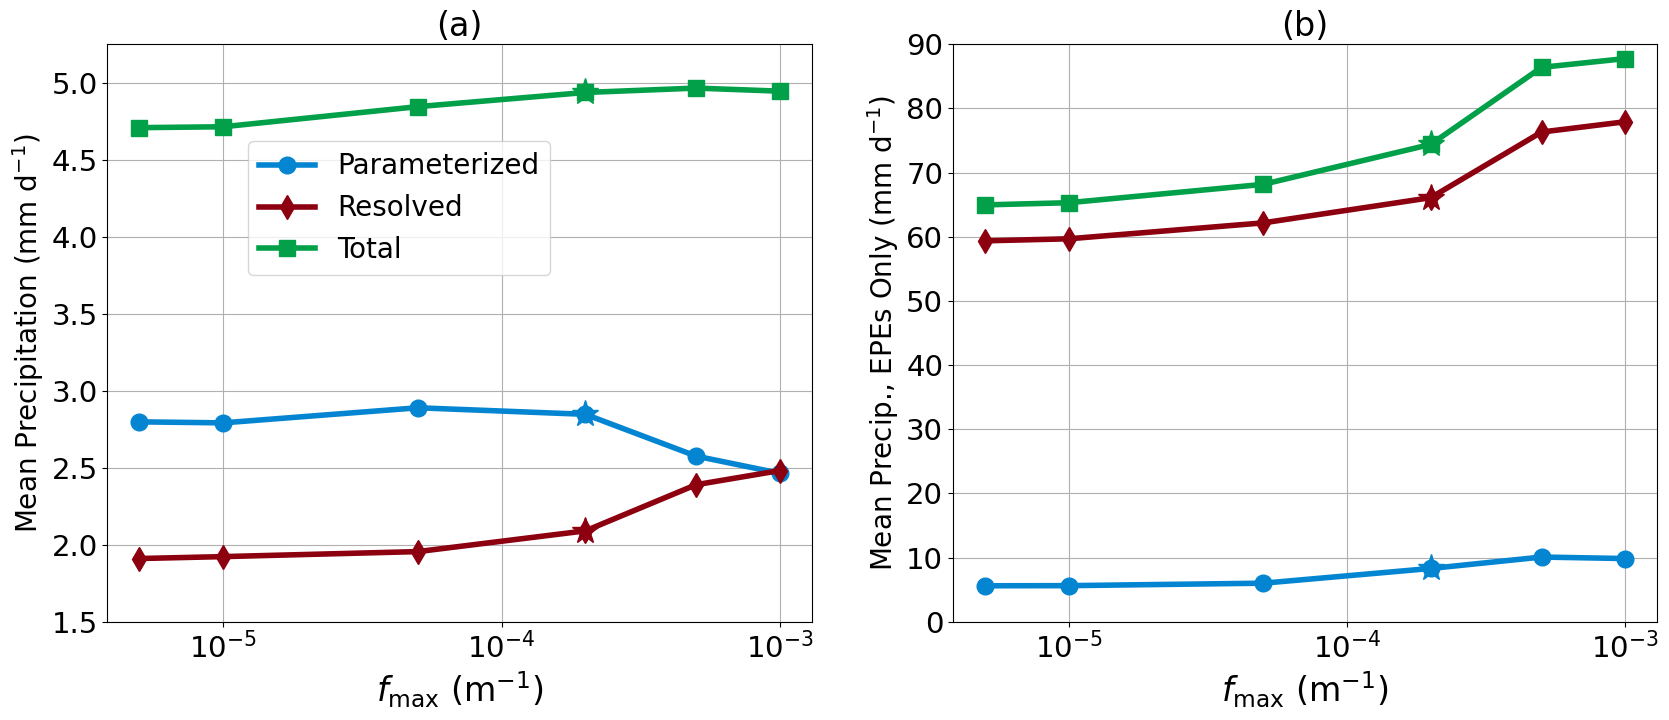

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
plt.subplots_adjust(hspace=0.3)

col_idx = 0

for ax_content in ax_contents:
    ax = axes[col_idx]

    ax.grid("on")

    ax.semilogx(fmax,
                     ax_content[0],
                     color = "xkcd:cerulean",
                     marker = "o",
                     linestyle = "solid",
                     label = "Parameterized",
                     linewidth = default_linewidth,
                     markersize = default_minor_markersize,
                    )
        
    ax.semilogx(2e-4,
                    ax_content[0][2],
                    color = "xkcd:cerulean",
                    marker= "*",
                    markersize =  default_markersize,
                   )
        
    ax.semilogx(fmax,
                     ax_content[1],
                     color = "xkcd:crimson",
                     marker = "d",
                     linestyle = "solid",
                     label = "Resolved",
                     linewidth = default_linewidth,
                     markersize = default_minor_markersize,
                    )
        
    ax.semilogx(2e-4,
                    ax_content[1][2],
                    color = "xkcd:crimson",
                    marker= "*",
                    markersize =  default_markersize,
                   )
    
    ax.semilogx(fmax,
                     ax_content[2],
                     color = "xkcd:emerald",
                     marker = "s",
                     linestyle = "solid",
                     label= "Total",
                     linewidth = default_linewidth,
                     markersize = default_minor_markersize,
                    )
    
    ax.semilogx(2e-4,
                    ax_content[2][2],
                    color = "xkcd:emerald",
                    marker= "*",
                    markersize =  default_markersize,
                    )

    #ax.set_xlim(left = min(fmax), right = max(fmax))
    ax.set_xlabel(r"$f_{\text{max}}$ ($\mathrm{m}^{-1}$)", fontsize = XAXIS_TITLE_FONT_SIZE)

    if col_idx == 0:
            
        ax.set_ylabel(r"Mean Precipitation (mm $\mathrm{d}^{-1}$)", fontsize = TITLE_FONT_SIZE)

        if figure_region == "tropical":
            ax.legend(fontsize = TITLE_FONT_SIZE, loc = (0.2, 0.6)) # tropical 
            ax.set_ylim(1.5, 5.25) # tropical

        if figure_region == "midlatitude":
            ax.legend(fontsize = TITLE_FONT_SIZE, loc = (0.2, 0.285)) # midlat
                
        ax.set_title("(a)", fontsize = XAXIS_TITLE_FONT_SIZE)

    if col_idx == 1:
            
        ax.set_ylabel(r"Mean Precip., EPEs Only (mm $\mathrm{d}^{-1}$)", fontsize = TITLE_FONT_SIZE)
        ax.set_title("(b)", fontsize = XAXIS_TITLE_FONT_SIZE)
            
        if figure_region == "tropical":
            ax.set_ylim(0, 90) # tropical

    ax.minorticks_off()
    
    col_idx += 1
    col_idx = col_idx % 2
    
# Save output
outfile_path = "images/" + "fmax-gallery-" + figure_region + ".png"
plt.savefig(outfile_path, dpi=600, bbox_inches='tight')

plt.show()